<a href="https://colab.research.google.com/github/estese-vi/netflix-movies-analysis/blob/main/netflix_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

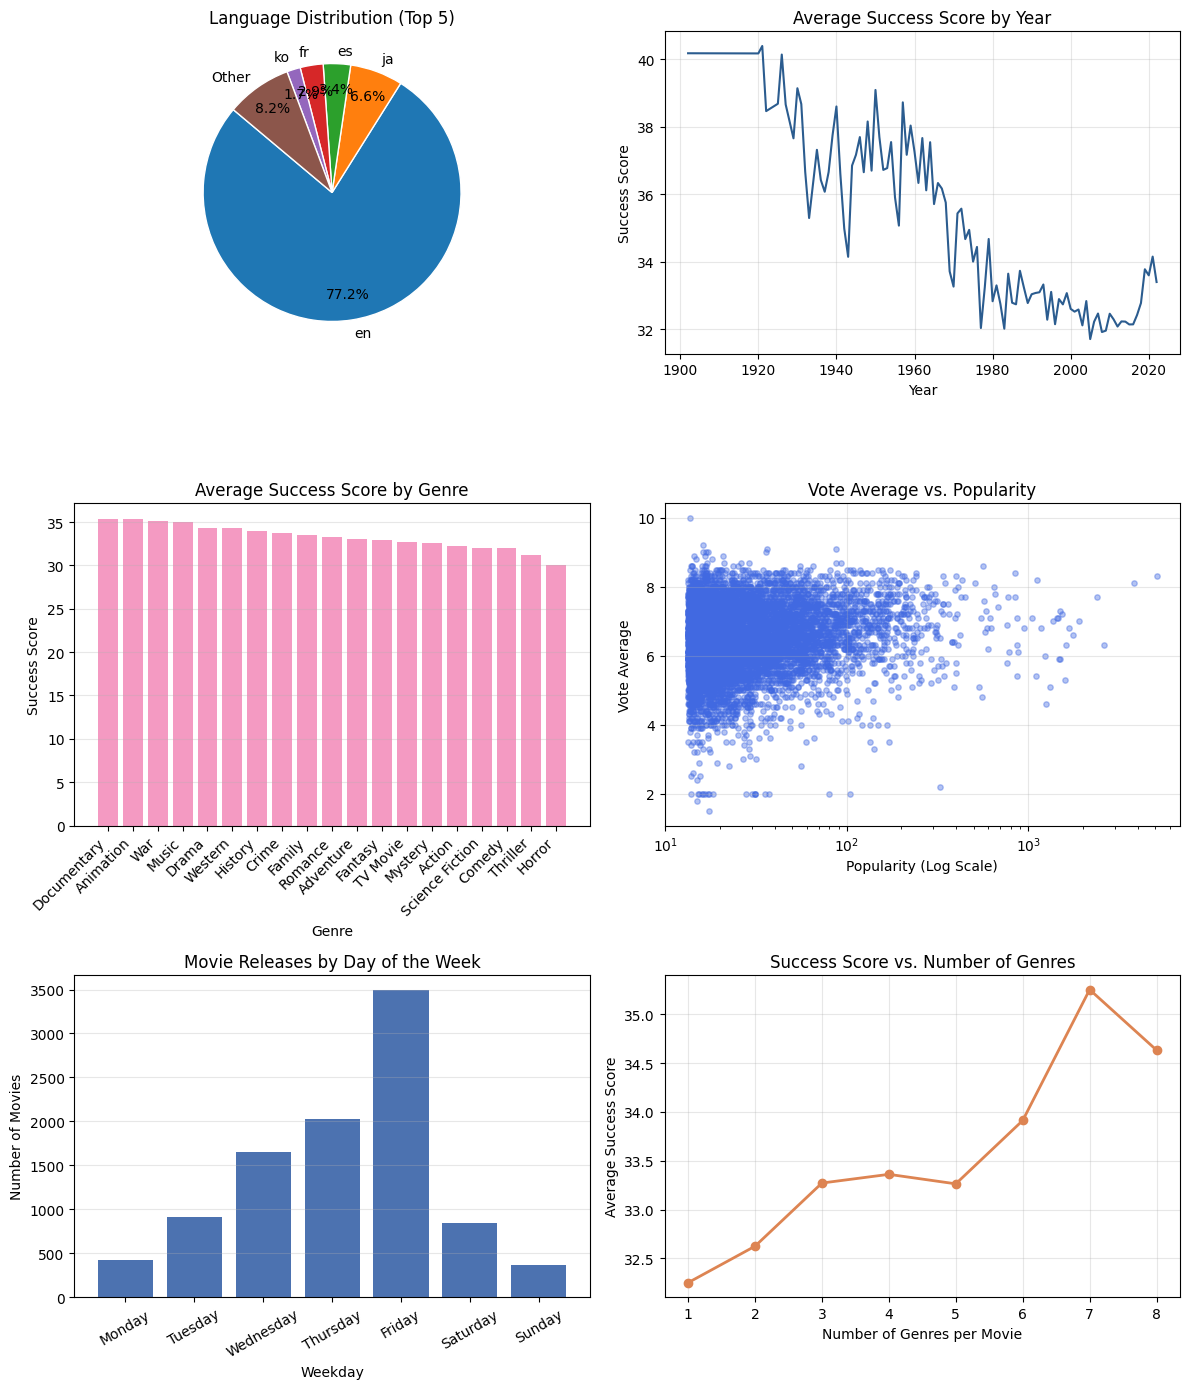

In [1]:
import pandas as pd
import matplotlib.pyplot as plt


# Loading data
url = "https://raw.githubusercontent.com/Pesimistixxx/NetflixMoviesDataset/master/netflix_titles.csv"
df = pd.read_csv(url, engine='python', encoding='utf-8')

# If automate downloading doesn't work
# Link for dataset downloading: https://www.kaggle.com/datasets/nalisha/netflix-movies-and-tv-shows-data-analysis/data
# df = pd.read_csv('mymoviedb (1).csv')

numeric_columns = ['Popularity', 'Vote_Count', 'Vote_Average']
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df = df.dropna(subset=['Vote_Count', 'Vote_Average'])

df['Release_Date'] = pd.to_datetime(df['Release_Date'], errors='coerce')
df['Year'] = df['Release_Date'].dt.year
df['Month'] = df['Release_Date'].dt.month
df['Day'] = df['Release_Date'].dt.day
df['Weekday'] = df['Release_Date'].dt.day_name()

def popularity_category(count):
    if pd.isna(count):
        return 'Unknown'
    elif count < 100:
        return 'Low (<100)'
    elif count < 1000:
        return 'Medium (100-999)'
    elif count < 5000:
        return 'High (1000-4999)'
    else:
        return 'Very High (5000+)'

df['Popularity_Category'] = df['Vote_Count'].apply(popularity_category)
df = df[df['Vote_Count'] > 0]

df['Popularity_Level'] = pd.cut(df['Popularity'],
                                 bins=[0, 100, 500, 1000, df['Popularity'].max()],
                                 labels=['Low', 'Medium', 'High', 'Very High'])

df['Genre_List'] = df['Genre'].str.split(', ')
df_exploded = df.explode('Genre_List')
df['Genre_Count'] = df['Genre'].str.count(',') + 1
df['Main_Genre'] = df['Genre'].str.split(', ').str[0]

lang_counts = df['Original_Language'].value_counts()
top5 = lang_counts.head(5)
# Sum the numbers of others languages (starting from 5-th place)
other_count = lang_counts.iloc[5:].sum()
# Create an element for "Other"
other_series = pd.Series([other_count], index=['Other'])
# Concatenate top-5 and "Other" in one common structure
lang_counts_with_other = pd.concat([top5, other_series])


rare_langs = lang_counts[lang_counts < 10].index
df['Language_Group'] = df['Original_Language'].apply(
    lambda x: 'Other' if x in rare_langs else str(x).upper()
)
df['Title'] = df['Title'].str.strip()
df['Overview'] = df['Overview'].str.strip()
df['Success_Score'] = (df['Popularity'] / df['Popularity'].max() * 50 +
                        df['Vote_Average'] / 10 * 50)
df['Title_Length'] = df['Title'].str.len()
df['Year_Month'] = df['Release_Date'].dt.to_period('M')
df['Quarter'] = df['Release_Date'].dt.quarter
df_yearly_rating = df.groupby('Year')['Success_Score'].mean().reset_index()
df_genre_rating = df.groupby('Main_Genre')['Success_Score'].mean().reset_index()
df_genre_rating = df_genre_rating.sort_values(by='Success_Score', ascending=False)

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 14))

# 1. Language distribution
axes[0, 0].pie(
    lang_counts_with_other,
    labels=lang_counts_with_other.index,
    autopct='%1.1f%%',
    pctdistance=0.8,
    startangle=140,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1}
)
axes[0, 0].set_title('Language Distribution (Top 5)')

# 2. Success Score per Year
axes[0, 1].plot(df_yearly_rating['Year'], df_yearly_rating['Success_Score'], color='#2b5c8f')
axes[0, 1].set_title('Average Success Score by Year')
axes[0, 1].set_xlabel('Year')
axes[0, 1].set_ylabel('Success Score')
axes[0, 1].grid(True, alpha=0.3)

# 3. Success Score per Genre
axes[1, 0].bar(df_genre_rating['Main_Genre'], df_genre_rating['Success_Score'], color='#f49ac2')
axes[1, 0].tick_params(axis='x', rotation=45)
for label in axes[1, 0].get_xticklabels():
    label.set_ha('right')
axes[1, 0].set_title('Average Success Score by Genre')
axes[1, 0].set_xlabel('Genre')
axes[1, 0].set_ylabel('Success Score')
axes[1, 0].grid(axis='y', alpha=0.3)

# 4. Vote Average vs. Popularity
axes[1, 1].scatter(df['Popularity'], df['Vote_Average'], color='royalblue', alpha=0.4, s=15)
axes[1, 1].set_xscale('log')
axes[1, 1].set_xlabel('Popularity (Log Scale)')
axes[1, 1].set_ylabel('Vote Average')
axes[1, 1].set_title('Vote Average vs. Popularity')
axes[1, 1].grid(True, alpha=0.3)

# 5. Releases by Day of the Week
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
weekday_counts = df['Weekday'].value_counts().reindex(weekday_order)

axes[2,0].bar(weekday_counts.index, weekday_counts.values, color='#4c72b0')
axes[2,0].set_title('Movie Releases by Day of the Week')
axes[2,0].set_xlabel('Weekday')
axes[2,0].set_ylabel('Number of Movies')
axes[2,0].tick_params(axis='x', rotation=30)
axes[2,0].grid(axis='y', alpha=0.3)

# 6. Average Success Score by Number of Genres
genre_count_perf = df.groupby('Genre_Count')['Success_Score'].mean()

axes[2,1].plot(genre_count_perf.index, genre_count_perf.values, marker='o', color='#dd8452', linewidth=2)
axes[2,1].set_title('Success Score vs. Number of Genres')
axes[2,1].set_xlabel('Number of Genres per Movie')
axes[2,1].set_ylabel('Average Success Score')
axes[2,1].set_xticks(genre_count_perf.index)
axes[2,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('dashboard.png', dpi=200, bbox_inches='tight')
plt.show()